In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential # type: ignore
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization # type: ignore
from tensorflow.keras.callbacks import EarlyStopping # type: ignore
import kagglehub # type: ignore

from tensorflow.keras.optimizers import Adam, RMSprop, SGD # type: ignore
from tensorflow.keras.layers import LeakyReLU # type: ignore
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.regularizers import l2 # type: ignore
import random

# Part A: Data Exploration and Preprocessing 

### Load and explore the dataset:

In [139]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

df = pd.read_csv(path+"/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()
df.info()
df.describe()

Path to dataset files: /home/snds/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [140]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

/tmp/ipykernel_82318/266577964.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [141]:
df.drop('customerID', axis=1, inplace=True)

In [142]:
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

In [143]:
cat_cols = df.select_dtypes(include='object').columns

df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

In [144]:
X = df.drop('Churn', axis=1)
y = df['Churn']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [145]:
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

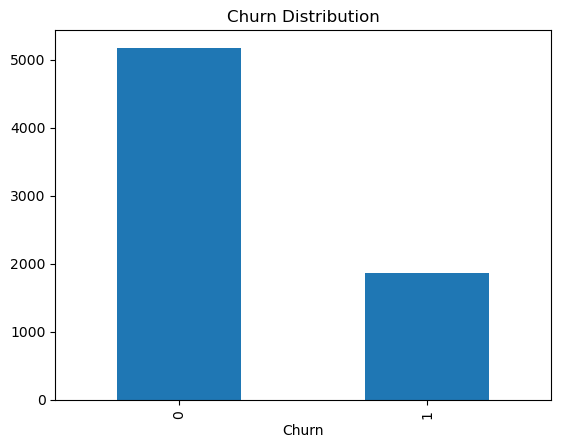

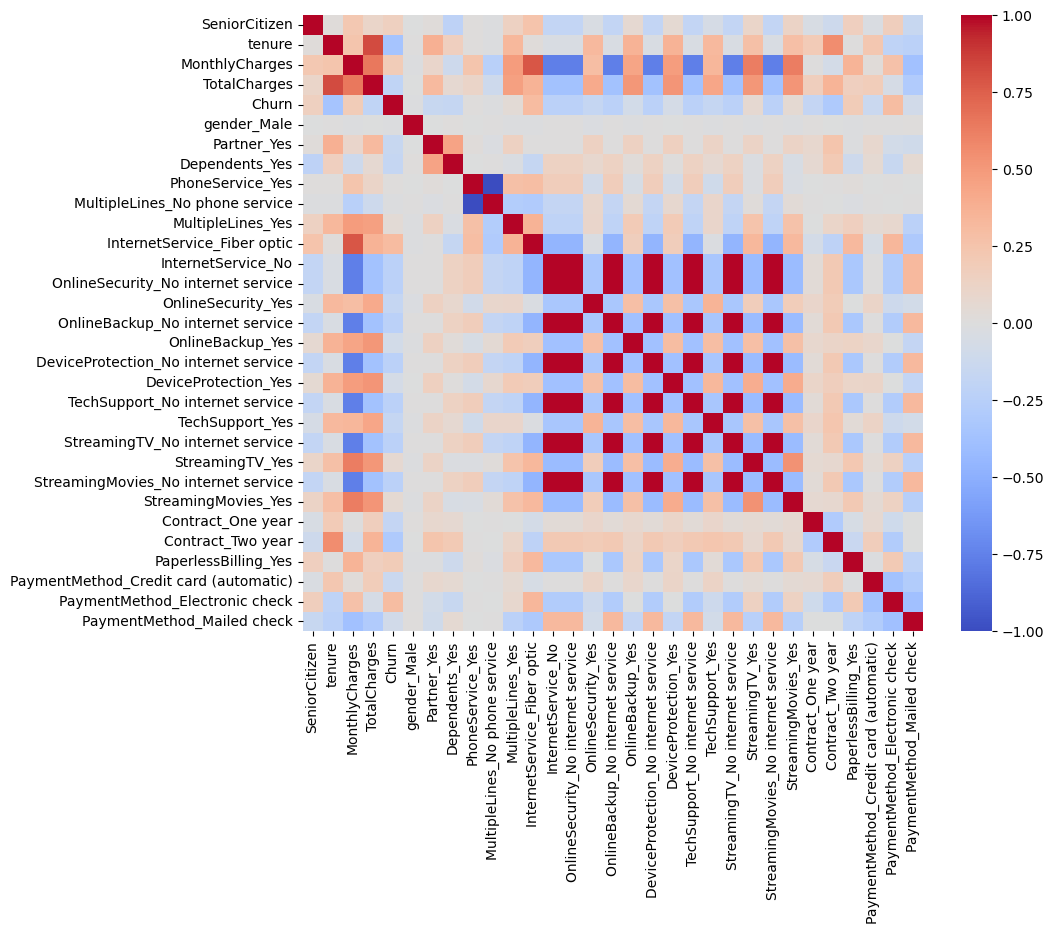

In [146]:
# Churn distribution
df['Churn'].value_counts().plot(kind='bar')
plt.title("Churn Distribution")
plt.show()

# Correlation heatmap
import seaborn as sns
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.show()

In [147]:
corr_matrix = df.corr()

churn_corr = corr_matrix['Churn'].abs().sort_values(ascending=False)

threshold = 0.1
features_to_keep = churn_corr[churn_corr >= threshold].index.tolist()
features_to_drop = churn_corr[churn_corr < threshold].index.tolist()


df_filtered = df[features_to_keep]

print(f"Original columns: {len(df.columns)}")
print(f"Columns kept: {len(df_filtered.columns)}")
print(f"Dropped due to low correlation: {features_to_drop}")

df= df_filtered

Original columns: 31
Columns kept: 22
Dropped due to low correlation: ['PaymentMethod_Mailed check', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'MultipleLines_Yes', 'MultipleLines_No phone service', 'PhoneService_Yes', 'gender_Male']


# Part B: Baseline Models

In [148]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print(classification_report(y_test, y_pred_lr))


              precision    recall  f1-score   support

           0       0.84      0.90      0.87       761
           1       0.69      0.57      0.62       296

    accuracy                           0.81      1057
   macro avg       0.77      0.74      0.75      1057
weighted avg       0.80      0.81      0.80      1057



In [149]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.81      0.90      0.85       761
           1       0.64      0.45      0.53       296

    accuracy                           0.77      1057
   macro avg       0.72      0.67      0.69      1057
weighted avg       0.76      0.77      0.76      1057



In [150]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print(classification_report(y_test, y_pred_xgb))

/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/xgboost/training.py:200: UserWarning: [17:30:25] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1772125072520/work/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.82      0.89      0.86       761
           1       0.65      0.51      0.57       296

    accuracy                           0.78      1057
   macro avg       0.73      0.70      0.71      1057
weighted avg       0.77      0.78      0.78      1057



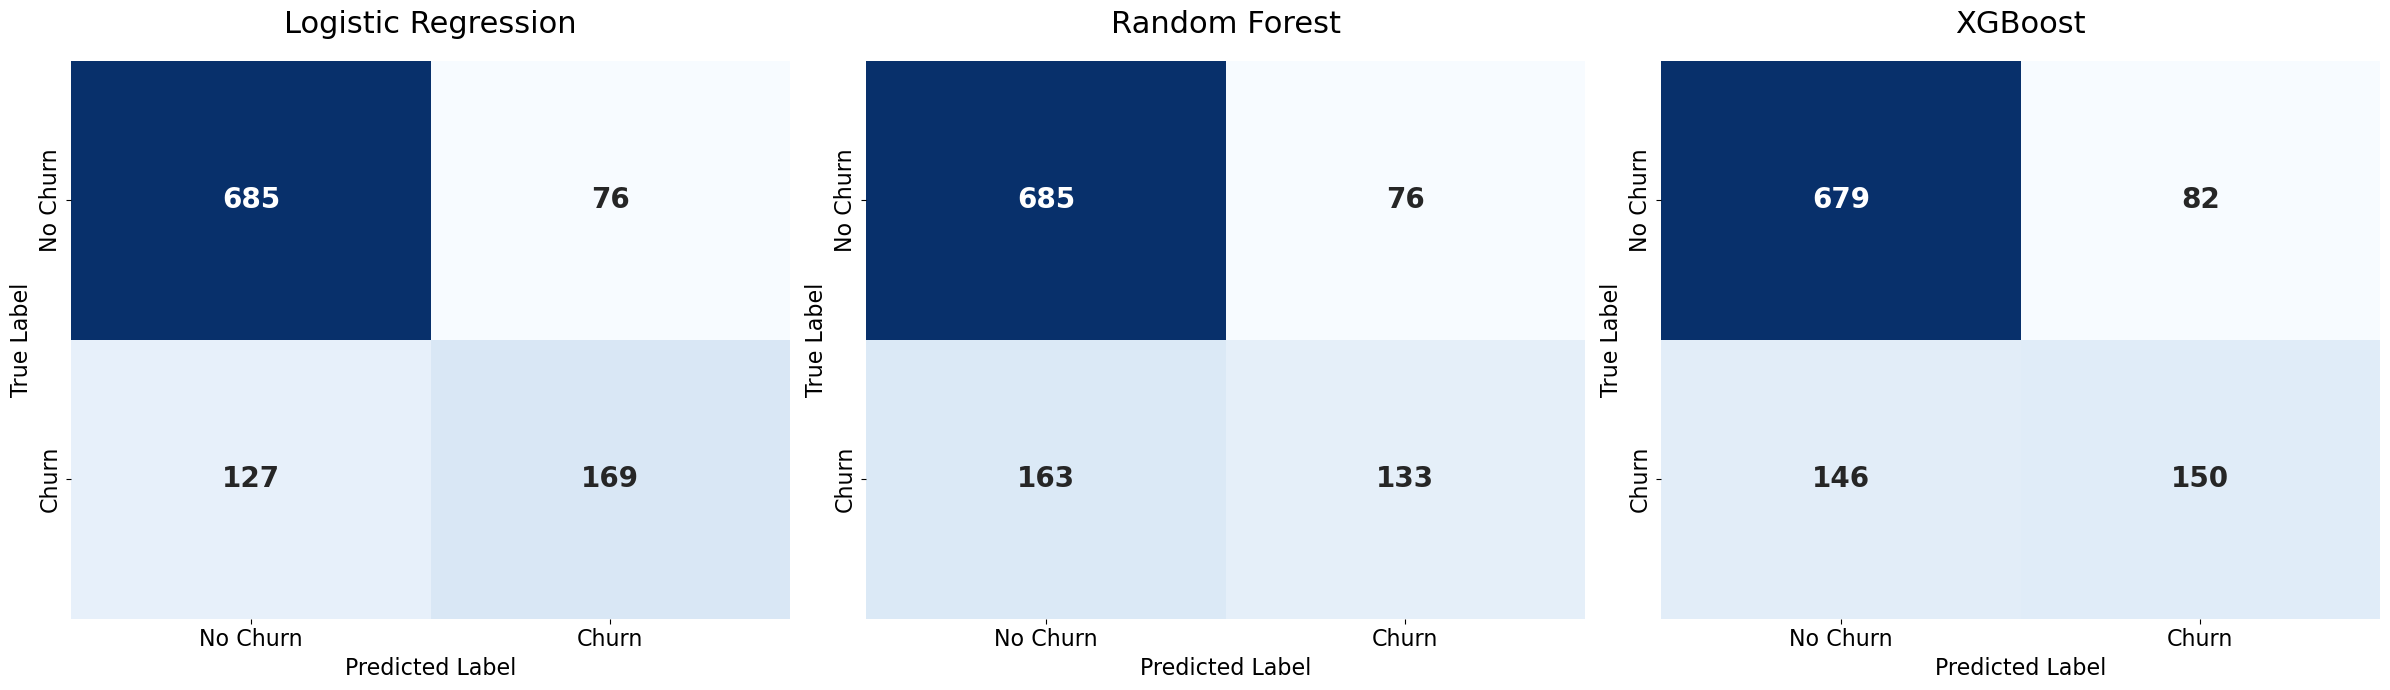

In [151]:

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

models = [
    (y_pred_lr, 'Logistic Regression'),
    (y_pred_rf, 'Random Forest'),
    (y_pred_xgb, 'XGBoost')
]

font_size = 16 

for i, (y_pred, title) in enumerate(models):
    cm = confusion_matrix(y_test, y_pred)
    

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Churn', 'Churn'], 
                yticklabels=['No Churn', 'Churn'],
                cbar=False,
                annot_kws={"size": 20, "weight": "bold"}) 
    
 
    axes[i].set_title(f'{title}', fontsize=22, pad=20)
    axes[i].set_xlabel('Predicted Label', fontsize=font_size)
    axes[i].set_ylabel('True Label', fontsize=font_size)
    
    
    axes[i].tick_params(axis='both', which='major', labelsize=font_size)

plt.tight_layout()
plt.show()

# Part C: Neural Network Architecture Design 

In [152]:
model1 = Sequential([
    Dense(20, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(1, activation='sigmoid')
])

model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history1 = model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50)

Epoch 1/50


/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6834 - loss: 0.5776 - val_accuracy: 0.7926 - val_loss: 0.4464
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7901 - loss: 0.4424 - val_accuracy: 0.8068 - val_loss: 0.4236
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7943 - loss: 0.4307 - val_accuracy: 0.8106 - val_loss: 0.4160
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7998 - loss: 0.4249 - val_accuracy: 0.8106 - val_loss: 0.4119
Epoch 5/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8006 - loss: 0.4214 - val_accuracy: 0.8097 - val_loss: 0.4113
Epoch 6/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8000 - loss: 0.4180 - val_accuracy: 0.8144 - val_loss: 0.4080
Epoch 7/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8020 - loss: 0.4165 - val_accuracy: 0.8172 - val_loss: 0.4086
Epoch 8/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8069 - loss: 0.4145 - val_accuracy: 0.8163 - val_

In [153]:
model2 = Sequential([
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50)

Epoch 1/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7570 - loss: 0.4817 - val_accuracy: 0.8106 - val_loss: 0.4147
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8024 - loss: 0.4302 - val_accuracy: 0.8106 - val_loss: 0.4104
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8073 - loss: 0.4175 - val_accuracy: 0.8059 - val_loss: 0.4060
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8097 - loss: 0.4123 - val_accuracy: 0.8201 - val_loss: 0.4042
Epoch 5/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8116 - loss: 0.4045 - val_accuracy: 0.8097 - val_loss: 0.4060
Epoch 6/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8095 - loss: 0.4018 - val_accuracy: 0.8087 - val_loss: 0.4096
Epoch 7/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8101 - loss: 0.3976 - val_accuracy: 0.8144 - val_loss: 0.4080
Epoch 8/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8178 - loss: 0.3909 - val_accuracy: 0.

In [154]:

model3 = Sequential([
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32),
    BatchNormalization(),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model3.compile(optimizer="adam", loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(patience=10, restore_best_weights=True)

history3 = model3.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=[early_stop]
)

Epoch 1/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7114 - loss: 0.5572 - val_accuracy: 0.7945 - val_loss: 0.4326
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7732 - loss: 0.4645 - val_accuracy: 0.8144 - val_loss: 0.4131
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7738 - loss: 0.4672 - val_accuracy: 0.8153 - val_loss: 0.4113
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7848 - loss: 0.4470 - val_accuracy: 0.8125 - val_loss: 0.4081
Epoch 5/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7907 - loss: 0.4392 - val_accuracy: 0.8125 - val_loss: 0.4045
Epoch 6/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7870 - loss: 0.4392 - val_accuracy: 0.8134 - val_loss: 0.4024
Epoch 7/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7913 - loss: 0.4399 - val_accuracy: 0.8106 - val_loss: 0.4027
Epoch 8/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7931 - loss: 0.4332 - val_accuracy: 0.

In [155]:

def build_model(activation_name, optimizer_name):
    model = Sequential()
    
   
    if activation_name == 'leaky_relu':
        model.add(Dense(64))
        model.add(LeakyReLU(alpha=0.01))
    else:
        model.add(Dense(64, activation=activation_name))
        
    
    model.add(Dense(32, activation=activation_name if activation_name != 'leaky_relu' else 'linear'))
    if activation_name == 'leaky_relu': model.add(LeakyReLU(alpha=0.01))
    
    model.add(Dense(16, activation=activation_name if activation_name != 'leaky_relu' else 'linear'))
    if activation_name == 'leaky_relu': model.add(LeakyReLU(alpha=0.01))
    
   
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(optimizer=optimizer_name, loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 2. Set up the experiments
activations = ['relu', 'tanh', 'leaky_relu']
optimizers = ['adam', 'rmsprop', 'sgd']
results = []


early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)


for act in activations:
    for opt in optimizers:
        print(f"Testing: Activation={act}, Optimizer={opt}...", end=" ")
        
        model = build_model(act, opt)
        history = model.fit(
            X_train, y_train, 
            validation_data=(X_val, y_val), 
            epochs=30, 
            batch_size=32, 
            callbacks=[early_stop], 
            verbose=0 
        )
        
        val_acc = max(history.history['val_accuracy'])
        results.append({'Activation': act, 'Optimizer': opt, 'Val_Accuracy': val_acc})
        print(f"Done. Best Val Acc: {val_acc:.4f}")


results_df = pd.DataFrame(results).sort_values(by='Val_Accuracy', ascending=False)
print("\n--- Final Comparison ---")
print(results_df)

Testing: Activation=relu, Optimizer=adam... Done. Best Val Acc: 0.8191
Testing: Activation=relu, Optimizer=rmsprop... Done. Best Val Acc: 0.8191
Testing: Activation=relu, Optimizer=sgd... Done. Best Val Acc: 0.7973
Testing: Activation=tanh, Optimizer=adam... Done. Best Val Acc: 0.8134
Testing: Activation=tanh, Optimizer=rmsprop... Done. Best Val Acc: 0.8106
Testing: Activation=tanh, Optimizer=sgd... Done. Best Val Acc: 0.8134
Testing: Activation=leaky_relu, Optimizer=adam... 

/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Done. Best Val Acc: 0.8116
Testing: Activation=leaky_relu, Optimizer=rmsprop... Done. Best Val Acc: 0.8068
Testing: Activation=leaky_relu, Optimizer=sgd... Done. Best Val Acc: 0.7917

--- Final Comparison ---
   Activation Optimizer  Val_Accuracy
0        relu      adam      0.819129
1        relu   rmsprop      0.819129
3        tanh      adam      0.813447
5        tanh       sgd      0.813447
6  leaky_relu      adam      0.811553
4        tanh   rmsprop      0.810606
7  leaky_relu   rmsprop      0.806818
2        relu       sgd      0.797348
8  leaky_relu       sgd      0.791667


# Part D: Addressing Class Imbalance

In [156]:
print(df['Churn'].value_counts())

imbalance_ratio = df['Churn'].value_counts()[0] / df['Churn'].value_counts()[1]
print(f"For every 1 person who churns, there are {imbalance_ratio:.2f} people who stay.")

Churn
0    5174
1    1869
Name: count, dtype: int64
For every 1 person who churns, there are 2.77 people who stay.


Running Baseline...
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Running Class Weights...
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Running SMOTE...
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


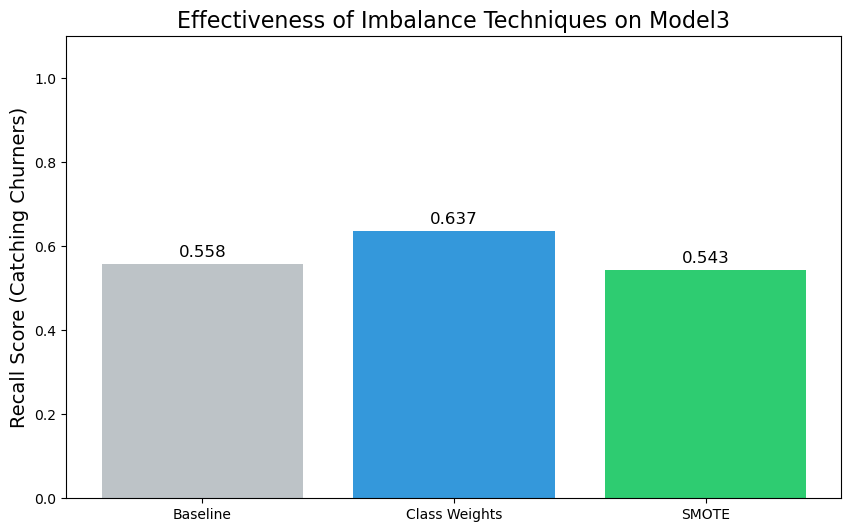


--- Final Recall Results ---
Baseline: 0.5576
Class Weights: 0.6367
SMOTE: 0.5432


In [157]:
from sklearn.metrics import recall_score


recalls = {}

# BASELINE
print("Running Baseline...")
model_base = model2 
model_base.fit(X_train, y_train, epochs=20, verbose=0)
y_pred_base = (model_base.predict(X_val) > 0.5).astype(int)
recalls["Baseline"] = recall_score(y_val, y_pred_base)

# CLASS WEIGHTS
print("Running Class Weights...")
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {0: weights[0], 1: weights[1]}

model_cw = model2
model_cw.fit(X_train, y_train, class_weight=class_weight_dict, epochs=20, verbose=0)
y_pred_weighted = (model_cw.predict(X_val) > 0.5).astype(int)
recalls["Class Weights"] = recall_score(y_val, y_pred_weighted)

# SMOTE 
print("Running SMOTE...")
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

model_smote = model2
model_smote.fit(X_train_res, y_train_res, epochs=20, verbose=0)
y_pred_smote = (model_smote.predict(X_val) > 0.5).astype(int)
recalls["SMOTE"] = recall_score(y_val, y_pred_smote)

# Comparison
plt.figure(figsize=(10, 6))
colors = ['#bdc3c7', '#3498db', '#2ecc71']
bars = plt.bar(recalls.keys(), recalls.values(), color=colors)


for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, round(yval, 3), ha='center', va='bottom', fontsize=12)

plt.ylim(0, 1.1)
plt.ylabel('Recall Score (Catching Churners)', fontsize=14)
plt.title('Effectiveness of Imbalance Techniques on Model3', fontsize=16)
plt.show()

print("\n--- Final Recall Results ---")
for method, score in recalls.items():
    print(f"{method}: {score:.4f}")

In [158]:
smote = SMOTE()
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [159]:
def build_optimized_model(n_layers, n_neurons, lr, dropout_rate, l2_reg):
    model = Sequential()
    
    # Input + First Hidden Layer
    model.add(Dense(n_neurons, activation='relu', kernel_regularizer=l2(l2_reg)))
    model.add(Dropout(dropout_rate))
    
    # Additional Layers
    for _ in range(n_layers - 1):
        model.add(Dense(n_neurons // 2, activation='relu', kernel_regularizer=l2(l2_reg)))
        model.add(Dropout(dropout_rate))
    
    # Output Layer
    model.add(Dense(1, activation='sigmoid'))
    
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.Recall()])
    return model

# 2. Define the "Search Space"
search_space = {
    'n_layers': [2, 3, 4],
    'n_neurons': [16, 32, 64],
    'lr': [0.1, 0.01, 0.001],
    'batch_size': [16, 32, 64],
    'dropout_rate': [0.2, 0.3, 0.5],
    'l2_reg': [0.01, 0.001]
}

best_f1 = 0
best_params = {}
best_model = None

print("🔎 Starting Randomized Search for the Best BALANCED Model...")

for i in range(10):
    params = {k: random.choice(v) for k, v in search_space.items()}
    
    temp_model = build_optimized_model(params['n_layers'], params['n_neurons'], 
                                       params['lr'], params['dropout_rate'], params['l2_reg'])
    
    history = temp_model.fit(X_train_sm, y_train_sm, validation_data=(X_val, y_val), 
                             epochs=20, batch_size=params['batch_size'], verbose=0)
    
    # 1. Get the metrics from the last epoch
    val_acc = history.history['val_accuracy'][-1]
    
    recall_key = [k for k in history.history.keys() if 'val' in k and 'recall' in k][0]
    val_recall = history.history[recall_key][-1]
    
    # 2. Get Precision (we need this for F1)
    # If your model predicts everything as churn, Precision will be very low (~0.25)
    y_val_pred = (temp_model.predict(X_val) > 0.5).astype(int)
    from sklearn.metrics import f1_score
    current_f1 = f1_score(y_val, y_val_pred)

    print(f"Iteration {i+1}: F1={current_f1:.4f} | Recall={val_recall:.4f} | Acc={val_acc:.4f}")
    
    # 3. Save the model based on the best F1-Score
    if current_f1 > best_f1:
        best_f1 = current_f1
        best_params = params
        best_model = tf.keras.models.clone_model(temp_model)
        best_model.set_weights(temp_model.get_weights())
        print(f"  ✨ New Champion! F1: {best_f1:.4f}")

print(f"\n🏆 Final Balanced Model Params: {best_params}")

🔎 Starting Randomized Search for the Best BALANCED Model...
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 1: F1=0.6261 | Recall=0.7410 | Acc=0.7670
  ✨ New Champion! F1: 0.6261
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 2: F1=0.0000 | Recall=0.0000 | Acc=0.7367
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 3: F1=0.6407 | Recall=0.7986 | Acc=0.7642
  ✨ New Champion! F1: 0.6407
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 4: F1=0.6279 | Recall=0.8345 | Acc=0.7396
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 5: F1=0.5868 | Recall=0.8813 | Acc=0.6733
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 6: F1=0.6371 | Recall=0.7230 | Acc=0.7831
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 7: F1=0.6181 | Recall=0.7626 | Acc=0.7519
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 8: F1=0.6505 | Recall=0.7698 | Acc=0.7822
  ✨ New Champion! F1: 0.6505
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Iteration 9: F1=0.6357 | Recall=0.8381 | Acc=0.7472
33/33 ━━━━━━━━━━━━━━━━━━━

In [160]:
# --- 1. Final Training to get History ---
final_model = build_optimized_model(
    best_params['n_layers'], 
    best_params['n_neurons'], 
    best_params['lr'], 
    best_params['dropout_rate'], 
    best_params['l2_reg']
)

# Use a slightly higher epoch count with EarlyStopping to find the true peak
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

final_history = final_model.fit(
    X_train_sm, y_train_sm, 
    validation_data=(X_val, y_val), 
    epochs=50, 
    batch_size=best_params['batch_size'],
    callbacks=[early_stop],
    verbose=1
)

# --- 2. Evaluate on Test Set ---
y_probs = final_model.predict(X_test).ravel()
y_pred = (y_probs > 0.5).astype(int)

print("\n--- Final Test Set Evaluation ---")
print(classification_report(y_test, y_pred))

Epoch 1/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7520 - loss: 0.5721 - recall_46: 0.7879 - val_accuracy: 0.7812 - val_loss: 0.5027 - val_recall_46: 0.7518
Epoch 2/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7692 - loss: 0.5318 - recall_46: 0.8157 - val_accuracy: 0.7794 - val_loss: 0.4907 - val_recall_46: 0.7482
Epoch 3/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7691 - loss: 0.5243 - recall_46: 0.8264 - val_accuracy: 0.7491 - val_loss: 0.5084 - val_recall_46: 0.7734
Epoch 4/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7626 - loss: 0.5207 - recall_46: 0.8143 - val_accuracy: 0.7595 - val_loss: 0.5133 - val_recall_46: 0.7590
Epoch 5/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7699 - loss: 0.5197 - recall_46: 0.8127 - val_accuracy: 0.7585 - val_loss: 0.5075 - val_recall_46: 0.8058
Epoch 6/50
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7637 - loss: 0.5180 - recall_46: 0.8080 - val_accuracy: 0.7652 - val_loss:

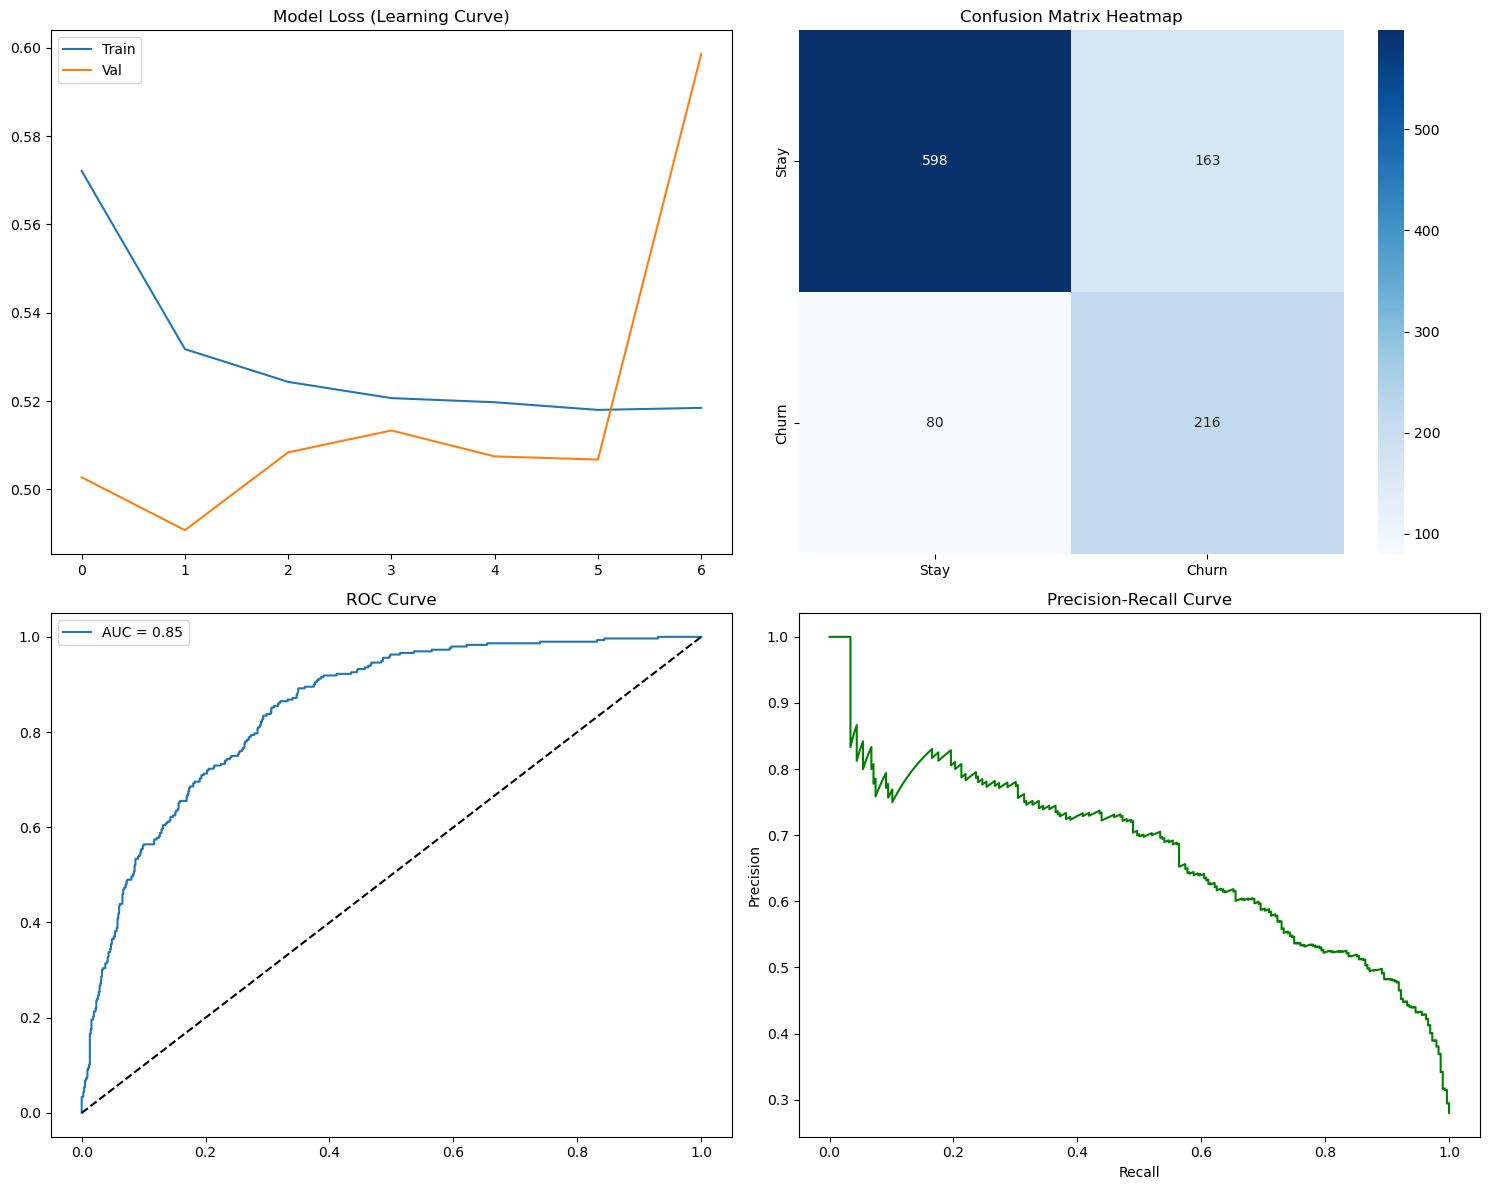

In [161]:

fig, axes = plt.subplots(2, 2, figsize=(15, 12))


axes[0, 0].plot(final_history.history['loss'], label='Train')
axes[0, 0].plot(final_history.history['val_loss'], label='Val')
axes[0, 0].set_title('Model Loss (Learning Curve)')
axes[0, 0].legend()


cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1],
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
axes[0, 1].set_title('Confusion Matrix Heatmap')


fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
axes[1, 0].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
axes[1, 0].plot([0, 1], [0, 1], 'k--')
axes[1, 0].set_title('ROC Curve')
axes[1, 0].legend()


prec, rec, _ = precision_recall_curve(y_test, y_probs)
axes[1, 1].plot(rec, prec, color='green')
axes[1, 1].set_title('Precision-Recall Curve')
axes[1, 1].set_xlabel('Recall')
axes[1, 1].set_ylabel('Precision')

plt.tight_layout()
plt.show()

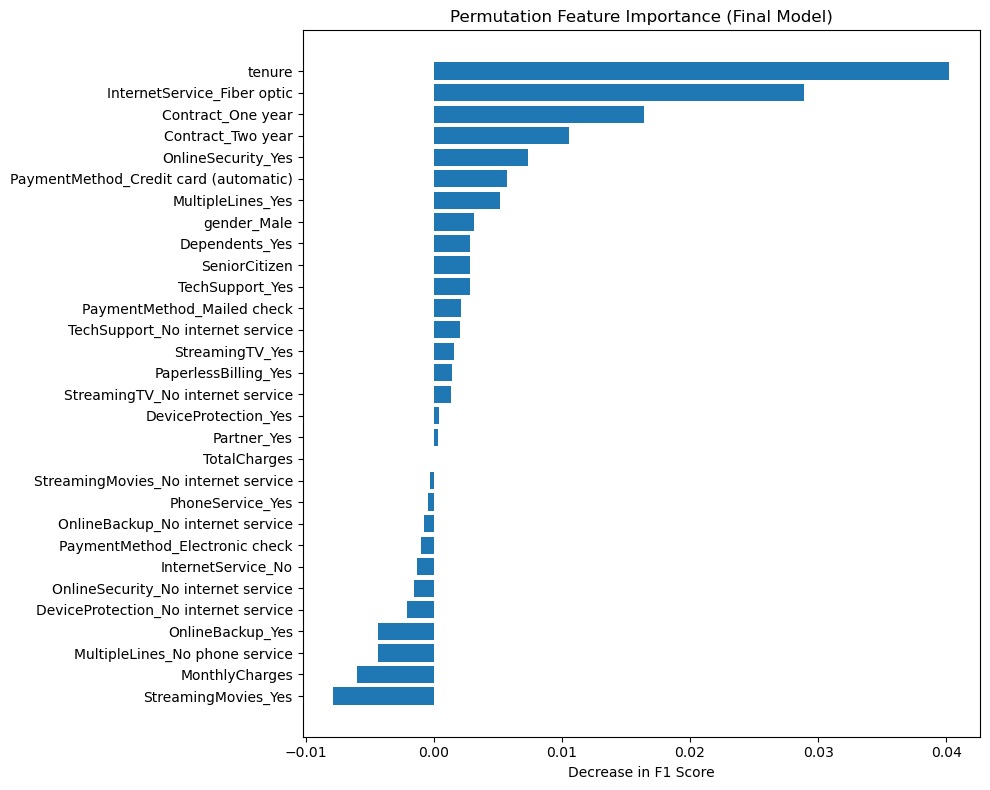

In [162]:
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

class KerasWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model):
        self.model = model
        self.classes_ = [0, 1]
    
    def fit(self, X, y):
      
        return self
    
    def predict(self, X):
        return (self.model.predict(X, verbose=0) > 0.5).astype(int)


wrapped_model = KerasWrapper(final_model)

perm_importance = permutation_importance(
    wrapped_model, 
    X_test, 
    y_test, 
    n_repeats=5, 
    scoring='f1', 
    random_state=42
)


sorted_idx = perm_importance.importances_mean.argsort()
feature_names = X.columns if hasattr(X, 'columns') else [f"Feature {i}" for i in range(X_test.shape[1])]

plt.figure(figsize=(10, 8))
plt.barh(np.array(feature_names)[sorted_idx], perm_importance.importances_mean[sorted_idx])
plt.xlabel("Decrease in F1 Score")
plt.title("Permutation Feature Importance (Final Model)")
plt.tight_layout()
plt.show()

/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_753
Received: inputs=['Tensor(shape=(100, 30))']
  warnings.warn(msg)
/home/snds/Miniforge3/envs/tf_env/lib/python3.10/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_753
Received: inputs=['Tensor(shape=(200, 30))']
  warnings.warn(msg)


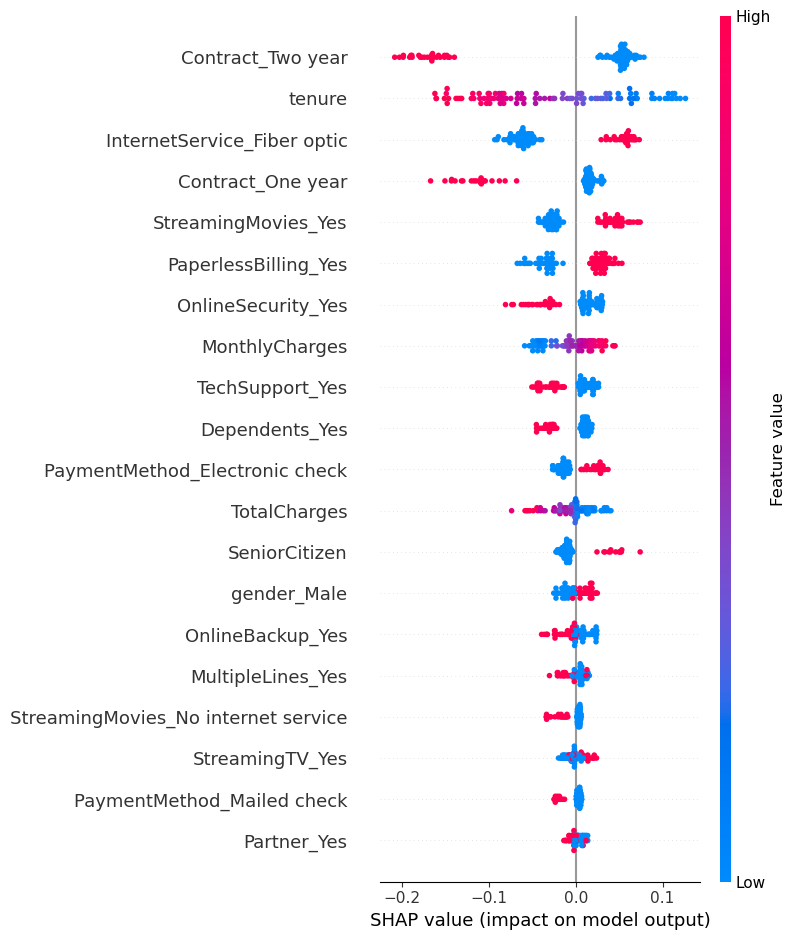

In [163]:
import shap

background = X_train[:100] 
explainer = shap.DeepExplainer(final_model, background)

shap_values = explainer.shap_values(X_test[:100])

if isinstance(shap_values, list):
    
    to_plot = shap_values[0]
else:
    to_plot = shap_values

if len(to_plot.shape) == 3:
    to_plot = to_plot.reshape(to_plot.shape[0], to_plot.shape[1])

plt.figure(figsize=(10, 6))
shap.summary_plot(to_plot, X_test[:100], feature_names=feature_names)